Iteration : 10327


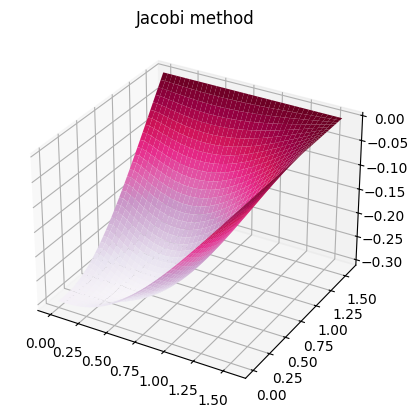

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


N = 40
h = np.pi/2/(N-1)
x = np.linspace(0, np.pi/2, N)
y = np.linspace(0, np.pi/2, N)

def f(x,y):
  return np.sin(2*x) * np.sin(2*y)

u0 = np.zeros((N,N))

max_iter = 100000
tol = 1e-6

def Jakobi(u0, max_iter, tol):
  un = u0.copy()

  n = 0
  while n == 0 or n < max_iter and np.linalg.norm(u - un) > tol:
    u = un

    un = np.zeros((N,N))
    for i in range(1, N-1):
      for j in range(1, N-1):
        un[i,j] = 1/(2 * (np.tan(x[i]) + np.tan(y[j]))) * (np.tan(x[i]) * (u[i+1,j] + u[i-1,j]) + np.tan(y[j]) * (u[i,j-1] + u[i,j+1]) - h**2 * f(x[i], y[j]))


    un[0,:] = un[1,:]
    un[-1,:] = np.zeros(N)
    un[:,0] = un[:,1]
    un[:,-1] = np.zeros(N)
    n +=1

  return u, n

u, n = Jakobi(u0,max_iter,tol)
X,Y = np.meshgrid(x,y)
fig, ax = plt.subplots(subplot_kw = {'projection':'3d'})
ax.plot_surface(X,Y,u, cmap = 'PuRd')
ax.set_title("Jacobi method")

print('Iteration :',n)


Iteration : 2940


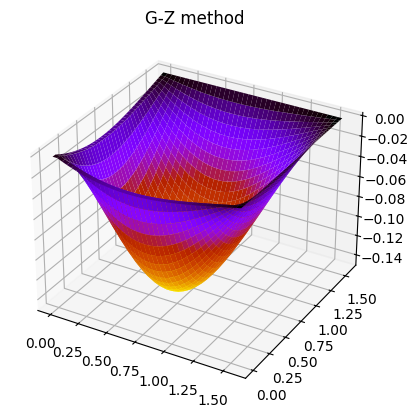

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 40
h = np.pi/2/(N-1)
x = np.linspace(0, np.pi/2, N)
y = np.linspace(0, np.pi/2, N)

def f(x,y):
  return np.sin(2*x) * np.sin(2*y)

u0 = np.zeros((N,N))

max_iter = 50000
tol = 1e-10
def G_Z(u0, max_iter, tol):
  un = u0.copy()
  n = 0
  while n == 0 or n < max_iter and np.linalg.norm(un - u) > tol:
    u = un

    un = np.zeros((N,N))
    for i in range(1, N-1):
      for j in range(1, N-1):
        un[i,j] = 1/(2 * (np.tan(x[i]) + np.tan(y[j]))) * (np.tan(x[i]) * (u[i+1,j] + un[i-1,j]) + np.tan(y[j]) * (un[i,j-1] + u[i,j+1]) - h**2 * f(x[i], y[j]))


    un[0,:] = un[1,:]
    un[-1,:] = 0
    un[:,0] = un[:,1]
    un[:,-1] = 0
    n+=1

  return u, n

u1, n = G_Z(u0,max_iter,tol)
X,Y = np.meshgrid(x,y)
fig, ax = plt.subplots(subplot_kw = {'projection':'3d'})
ax.plot_surface(X, Y, u1, cmap = 'gnuplot_r')
ax.set_title("G-Z method")

print('Iteration :',n)


Iteration : 209


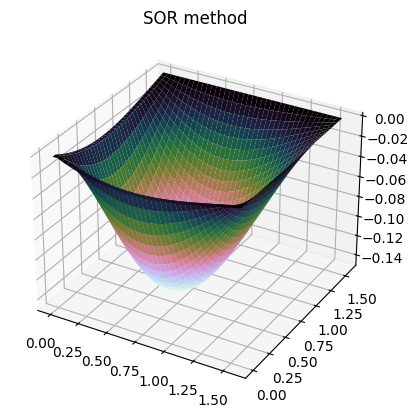

In [ ]:
N = 40
h = np.pi/2/(N-1)
x = np.linspace(0, np.pi/2, N)
y = np.linspace(0, np.pi/2, N)

def f(x,y):
  return np.sin(2*x) * np.sin(2*y)

u0 = np.zeros((N,N))
w = 1.9
max_iter = 50000
tol = 1e-10

def SOR(u0, max_iter, tol):
  un = u0.copy()
  n = 0
  while n == 0 or n < max_iter and np.linalg.norm(u - un) > tol:
    u = un

    un = np.zeros((N,N))
    for i in range(1, N-1):
      for j in range(1, N-1):
        un[i,j] = (1 - w) * u[i,j] + w * 1/(2 * (np.tan(x[i]) + np.tan(y[j]))) * (np.tan(x[i]) * (u[i+1,j] + un[i-1,j]) + np.tan(y[j]) * (un[i,j-1] + u[i,j+1]) - h**2 * f(x[i], y[j]))


    un[0,:] = un[1,:]
    un[-1,:] = np.zeros(N)
    un[:,0] = un[:,1]
    un[:,-1] = np.zeros(N)
    n +=1

  return u, n

u1, n = SOR(u0,max_iter,tol)
X,Y = np.meshgrid(x,y)
fig, ax = plt.subplots(subplot_kw = {'projection':'3d'})
ax.plot_surface(X, Y, u1, cmap = 'cubehelix_r')
ax.set_title("SOR method")


print('Iteration :',n)
